### Comparison between SteadierCom and experimental results

In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


import sys
sys.path.append("../functions/")
import compare_inter_exp_sim.venturelli2018 as venturelli2018
import compare_inter_exp_sim.correlation as correlation


In [52]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [53]:
signal_exp = venturelli2018.load_experimental_results()

/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_18922/3111039850.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  ax = sns.kdeplot(signal_exp,shade=True)


Text(0.5, 0, 'gLV coefficient')

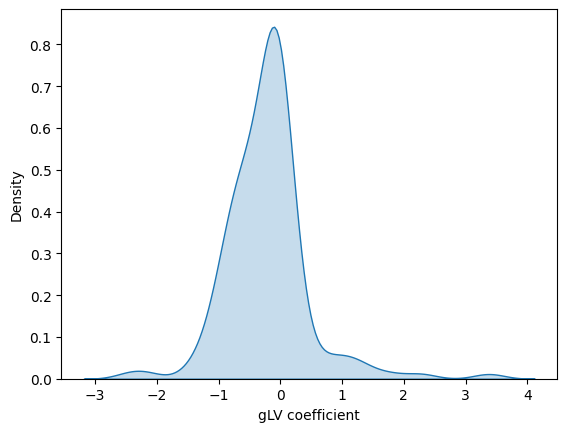

In [54]:
ax = sns.kdeplot(signal_exp,shade=True)
ax.set_xlabel("gLV coefficient")

In [55]:
simulation_dict = venturelli2018.load_simulation_results()


## Cooperation and competition - SteadierCom

In [56]:
results_corr_df,results_corr_member_df = venturelli2018.find_correlations(simulation_dict,signal_exp)

steadycom
steadiercom
steadiercom
smetana


In [57]:
results_corr_df_bh = results_corr_df.copy()
results_corr_df_bh["rank"] = results_corr_df_bh["p-value"].rank()
results_corr_df_bh["p-value BH critical"] = (results_corr_df_bh["rank"]/results_corr_df_bh.shape[0])*0.05

results_corr_df_bh["pass BH test"] = results_corr_df_bh["p-value"]<results_corr_df_bh["p-value BH critical"]


In [58]:
results_corr_member_df_bh = results_corr_member_df.copy()
results_corr_member_df_bh["rank"] = results_corr_member_df_bh["p-value"].rank()
results_corr_member_df_bh["p-value BH critical"] = (results_corr_member_df_bh["rank"]/results_corr_member_df_bh.shape[0])*0.05
results_corr_member_df_bh["pass BH test"] = results_corr_member_df_bh["p-value"]<results_corr_member_df_bh["p-value BH critical"]


In [59]:
signal_exp.index.names

FrozenList(['member_second', 'member_main'])

In [60]:
results_corr_df_bh = results_corr_df_bh.dropna()
results_corr_df_bh.query("`pass BH test`")

r  \
coop_or_comp simulation_method condition                              metric                          
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate -0.200255   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.207101   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate  0.186904   

                                                                                            p-value  \
coop_or_comp simulation_method condition                              metric                          
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.002359   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.001662   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate  0.004538   

                                                                                           #simulated  \
coop_or_comp simulation_method condition                              metric                            
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate       110.0   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate       110.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate       110.0   

                                                                                           #not simulated  \
coop_or_comp simulation_method condition                              metric                                
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate            34.0   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate            34.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate            34.0   

                                                                                           rank  \
coop_or_comp simulation_method condition                              metric                      
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate   2.0   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate   1.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate   3.0   

                                                                                           p-value BH critical  \
coop_or_comp simulation_method condition                              metric                                     
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate             0.003704   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate             0.001852   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate             0.005556   

                                                                                           pass BH test  
coop_or_comp simulation_method condition                              metric                             
comp         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate          True  
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate          True  
                               SteadierCom - Fixed growth & abundance frequency*mass_rate          True

#### SteadierCom - scatterplot - frequency*mass_rate

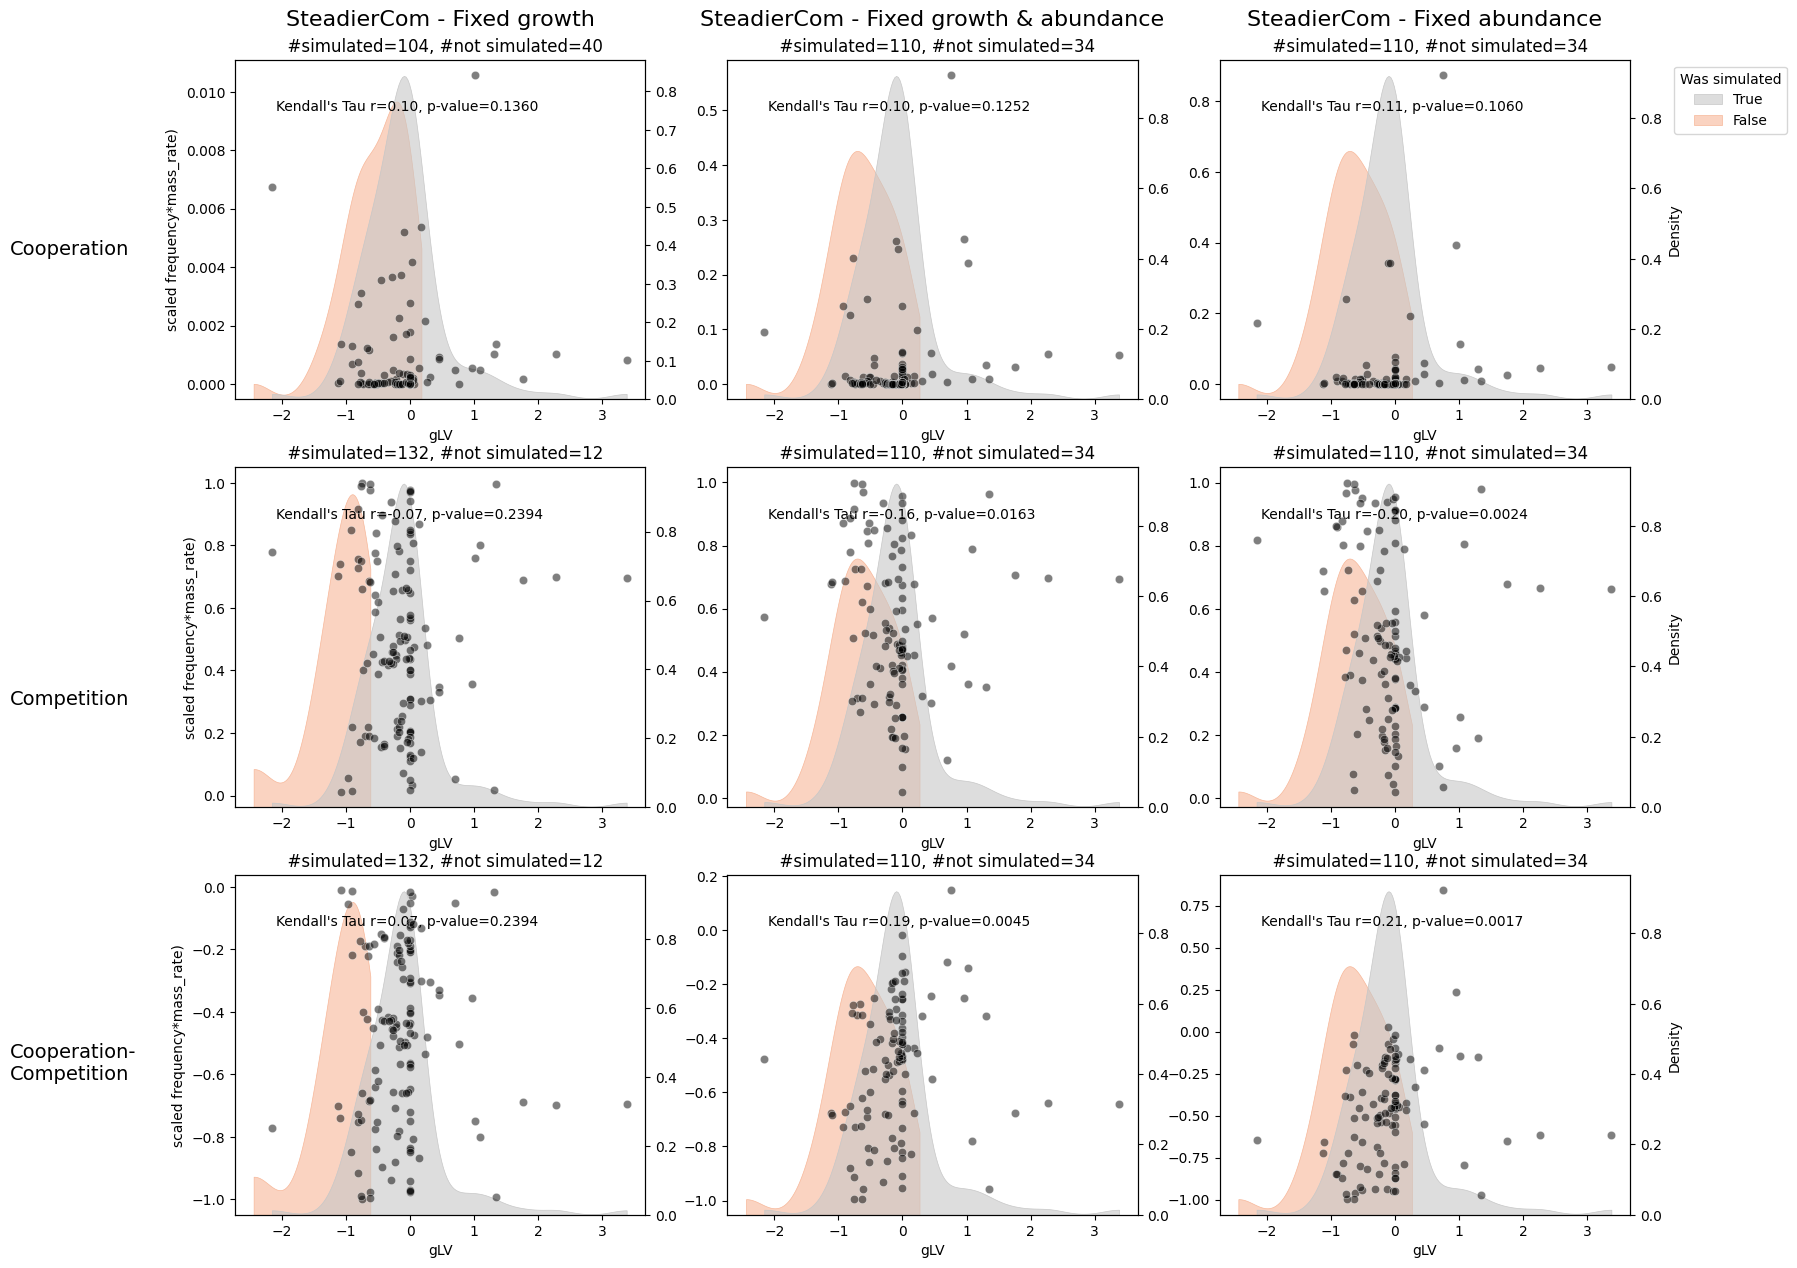

In [ ]:
fig,axs,axs_twin,not_simulated = correlation.make_scatterplots_simulation_method(simulation_dict,
                                                                                 signal_exp,
                                                                                 simulation_method="steadiercom",
                                                                                 metric="frequency*mass_rate",
                                                                                )

### Member-wise correlation with experimental data
None of the results are significant...

In [61]:
results_corr_member_df_bh.query("`p-value` < 0.05 & r < 0").xs("comp",drop_level=False).sort_index()

r  \
coop_or_comp simulation_method condition                              metric              member             
comp         steadiercom       SteadierCom - Fixed abundance          frequency           BO     -0.555556   
                                                                      frequency*mass_rate BU     -0.555556   
                                                                                          BV     -0.555556   
                                                                                          ER     -0.547723   
                               SteadierCom - Fixed growth             frequency*mass_rate BO     -0.636364   
                                                                                          BT     -0.490909   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO     -0.555556   
                                                                                          BV     -0.555556   
             steadycom         SteadyCom - Nothing fixed              rate?               EL     -0.611111   

                                                                                                   p-value  \
coop_or_comp simulation_method condition                              metric              member             
comp         steadiercom       SteadierCom - Fixed abundance          frequency           BO      0.028609   
                                                                      frequency*mass_rate BU      0.028609   
                                                                                          BV      0.028609   
                                                                                          ER      0.045056   
                               SteadierCom - Fixed growth             frequency*mass_rate BO      0.005707   
                                                                                          BT      0.040532   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO      0.028609   
                                                                                          BV      0.028609   
             steadycom         SteadyCom - Nothing fixed              rate?               EL      0.024741   

                                                                                                  #simulated  \
coop_or_comp simulation_method condition                              metric              member               
comp         steadiercom       SteadierCom - Fixed abundance          frequency           BO            10.0   
                                                                      frequency*mass_rate BU            10.0   
                                                                                          BV            10.0   
                                                                                          ER            10.0   
                               SteadierCom - Fixed growth             frequency*mass_rate BO            11.0   
                                                                                          BT            11.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO            10.0   
                                                                                          BV            10.0   
             steadycom         SteadyCom - Nothing fixed              rate?               EL             9.0   

                                                                                                  #not simulated  \
coop_or_comp simulation_method condition                              metric              member                   
comp         steadiercom       SteadierCom - Fixed abundance          frequency           BO                 2.0   
                                                                      frequency*mass_rate BU          

In [62]:
results_corr_member_df_bh.query("`p-value` < 0.05 & r > 0").xs("coop-comp",drop_level=False).sort_index()

r  \
coop_or_comp simulation_method condition                              metric              member             
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency           BO      0.511111   
                                                                                          BU      0.555556   
                                                                      frequency*mass_rate BO      0.555556   
                                                                                          BU      0.644444   
                                                                                          BV      0.511111   
                                                                                          ER      0.547723   
                               SteadierCom - Fixed growth             frequency*mass_rate BO      0.636364   
                                                                                          BT      0.490909   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO      0.644444   
                                                                                          BU      0.644444   
                                                                                          BV      0.511111   

                                                                                                   p-value  \
coop_or_comp simulation_method condition                              metric              member             
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency           BO      0.046623   
                                                                                          BU      0.028609   
                                                                      frequency*mass_rate BO      0.028609   
                                                                                          BU      0.009148   
                                                                                          BV      0.046623   
                                                                                          ER      0.045056   
                               SteadierCom - Fixed growth             frequency*mass_rate BO      0.005707   
                                                                                          BT      0.040532   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO      0.009148   
                                                                                          BU      0.009148   
                                                                                          BV      0.046623   

                                                                                                  #simulated  \
coop_or_comp simulation_method condition                              metric              member               
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency           BO            10.0   
                                                                                          BU            10.0   
                                                                      frequency*mass_rate BO            10.0   
                                                                                          BU            10.0   
                                                                                          BV            10.0   
                                                                                          ER            10.0   
                               SteadierCom - Fixed growth             frequency*mass_rate BO            11.0   
                                                                                          BT            11.0   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate BO            10.0   
           

<Axes: xlabel='member_second'>

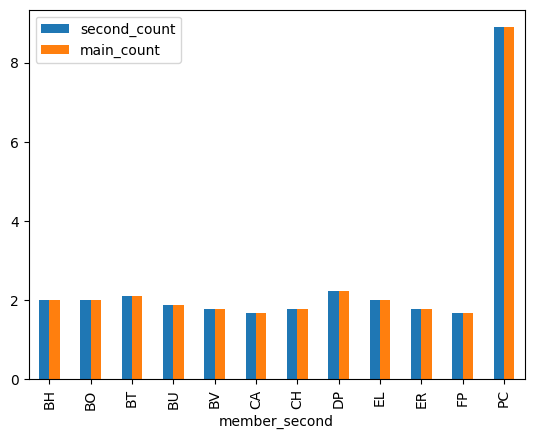

In [19]:

not_simulated_df = pd.DataFrame(not_simulated)
not_simulated_df.columns = ["member_second","member_main"]

counts = (not_simulated_df.groupby("member_second")
          .agg(second_count=("member_second","size"), main_count=("member_main","size"))
          .fillna(0)
          /9)

counts.plot(kind="bar")

#### SteadyCom - scatterplot - rate?

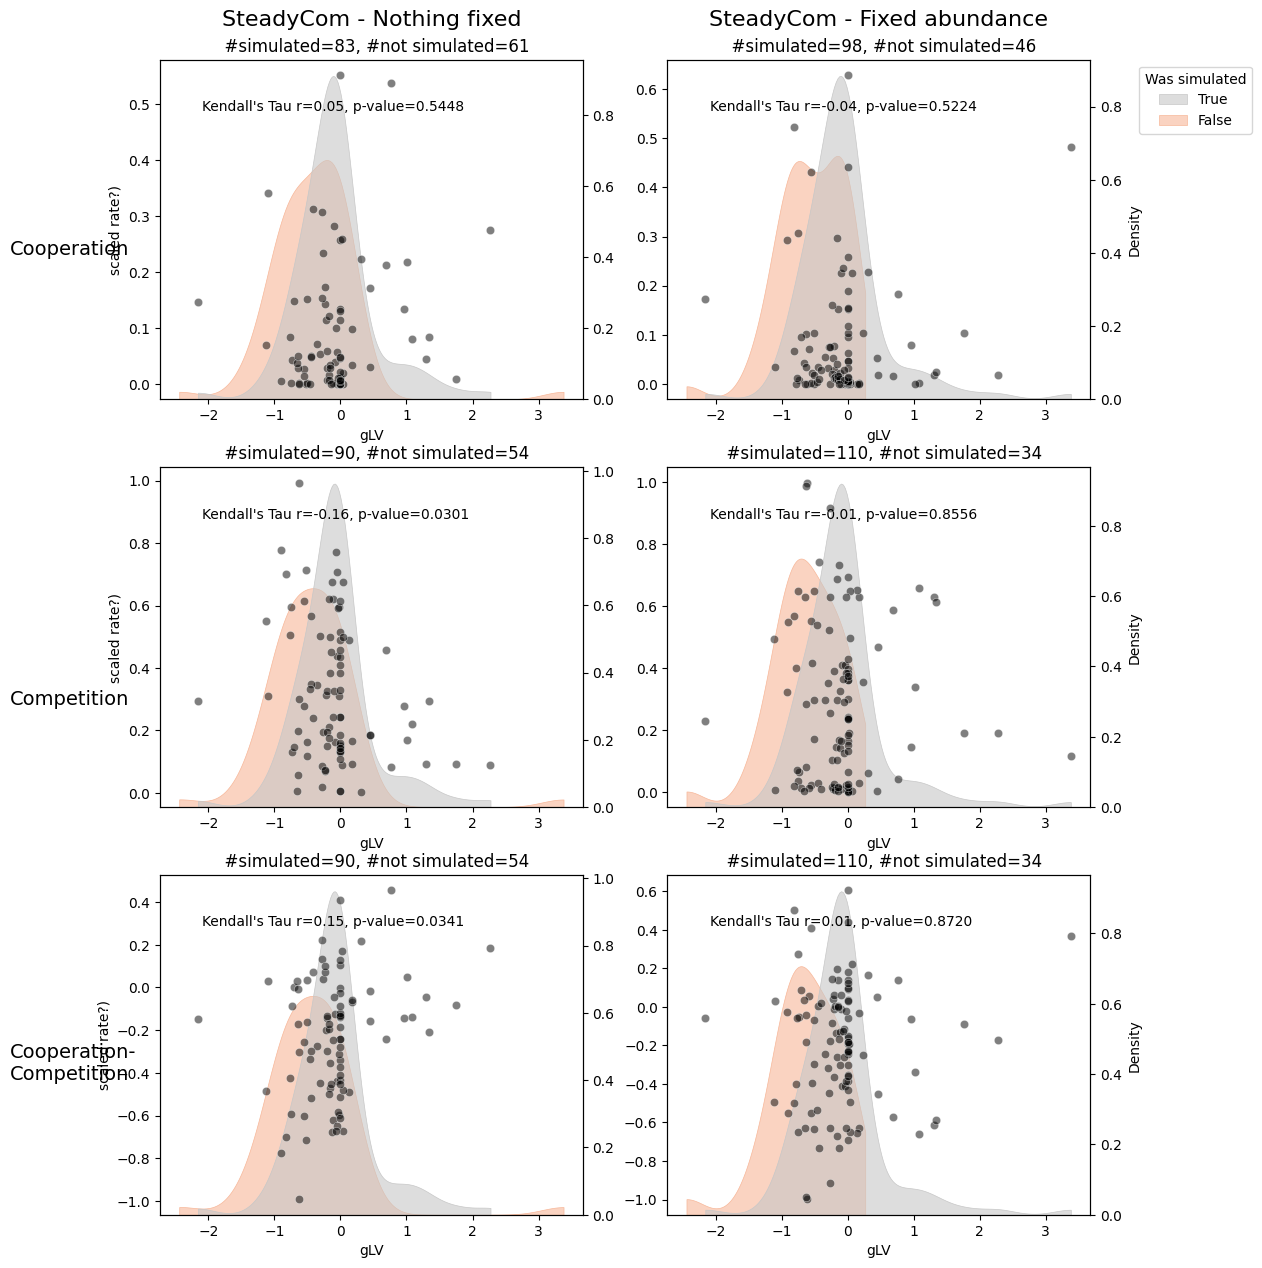

In [20]:
fig,axs,axs_twin,not_simulated = correlation.make_scatterplots_simulation_method(simulation_dict,
                                                                                 signal_exp,
                                                                                 simulation_method="steadycom",
                                                                                 metric="rate?")

<Axes: xlabel='member_second'>

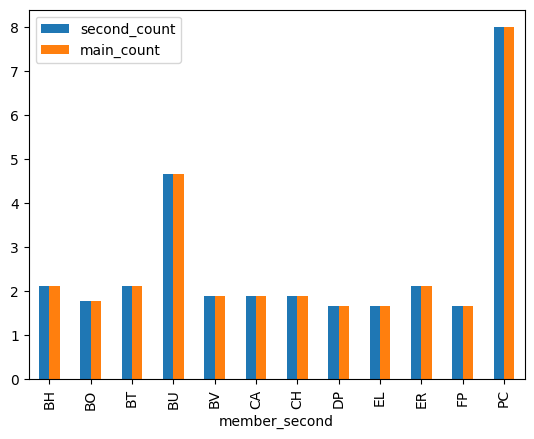

In [21]:

not_simulated_df = pd.DataFrame(not_simulated)
not_simulated_df.columns = ["member_second","member_main"]

counts = (not_simulated_df.groupby("member_second")
          .agg(second_count=("member_second","size"), main_count=("member_main","size"))
          .fillna(0)
          /9)

counts.plot(kind="bar")

## Diagnostic for cooperation and competition

In [28]:
import compare_inter_exp_sim.diagnostic as diagnostic

In [29]:
support_df = diagnostic.identify_support(signal_exp)
support_df.sort_index(ascending=False)

,,positive_support,negative_support,total,no-skill line
coop,0.001,22,122,144,0.152778
comp,0.001,91,53,144,0.631944


**Permutation test for classification**

Classification is working better for cooperation than competition, and SteadierCom is giving the best results.

In [30]:
permutation_results = diagnostic.find_pvalues_of_PR(simulation_dict=simulation_dict,
                              signal_exp=signal_exp)


results_pr_auc_df_bh = permutation_results.copy()
results_pr_auc_df_bh["rank"] = results_pr_auc_df_bh["p_value"].rank()
results_pr_auc_df_bh["p-value BH critical"] = (results_pr_auc_df_bh["rank"]/results_pr_auc_df_bh.shape[0])*0.05
results_pr_auc_df_bh["pass BH test"] = results_pr_auc_df_bh["p_value"]<results_pr_auc_df_bh["p-value BH critical"]
results_pr_auc_df_bh.sort_values("p-value BH critical")

p_value  \
role simulation_method condition                              metric              exp_thresh            
coop steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate 0.001        0.0000   
                       SteadierCom - Fixed growth & abundance frequency*mass_rate 0.001        0.0006   
                       SteadierCom - Fixed growth             frequency*mass_rate 0.001        0.0010   
     steadycom         SteadyCom - Nothing fixed              rate?               0.001        0.0107   
comp steadycom         SteadyCom - Nothing fixed              rate?               0.001        0.0686   
coop steadycom         SteadyCom - Fixed abundance            rate?               0.001        0.2017   
comp steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate 0.001        0.2714   
                       SteadierCom - Fixed growth & abundance frequency*mass_rate 0.001        0.4144   
     steadycom         SteadyCom - Fixed abundance            rate?               0.001        0.5291   
     steadiercom       SteadierCom - Fixed growth             frequency*mass_rate 0.001        0.6881   

                                                                                              rank  \
role simulation_method condition                              metric              exp_thresh         
coop steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate 0.001        1.0   
                       SteadierCom - Fixed growth & abundance frequency*mass_rate 0.001        2.0   
                       SteadierCom - Fixed growth             frequency*mass_rate 0.001        3.0   
     steadycom         SteadyCom - Nothing fixed              rate?               0.001        4.0   
comp steadycom         SteadyCom - Nothing fixed              rate?               0.001        5.0   
coop steadycom         SteadyCom - Fixed abundance            rate?               0.001        6.0   
comp steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate 0.001        7.0   
                       SteadierCom - Fixed growth & abundance frequency*mass_rate 0.001        8.0   
     steadycom         SteadyCom - Fixed abundance            rate?               0.001        9.0   
     steadiercom       SteadierCom - Fixed growth             frequency*mass_rate 0.001       10.0   

                                                                                              p-value BH critical  \
role simulation_method condition                              metric              exp_thresh                        
coop steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate 0.001                     0.005   
                       SteadierCom - Fixed growth & abundance frequency*mass_rate 0.001                     0.010   
                       SteadierCom - Fixed growth             frequency*mass_rate 0.001                     0.015   
     steadycom         SteadyCom - Nothing fixed              rate?               0.001                     0.020   
comp steadycom         SteadyCom - Nothing fixed              rate?               0.001                     0.025   
coop steadycom         SteadyCom - Fixed abundance            rate?               0.001                     0.030   
comp steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate 0.001                     0.035   
                       SteadierCom - Fixed growth & abundance frequency*mass_rate 0.001                     0.040   
     steadycom         SteadyCom - Fixed abundance            rate?               0.001                     0.045   
     steadiercom       SteadierCom - Fixed growth             frequency*mass_rate 0.001                     0.050   

                                                                                              pass BH test  
role simulation_method condition                              metric              exp_thresh  

### SteadierCom - PR curves

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.


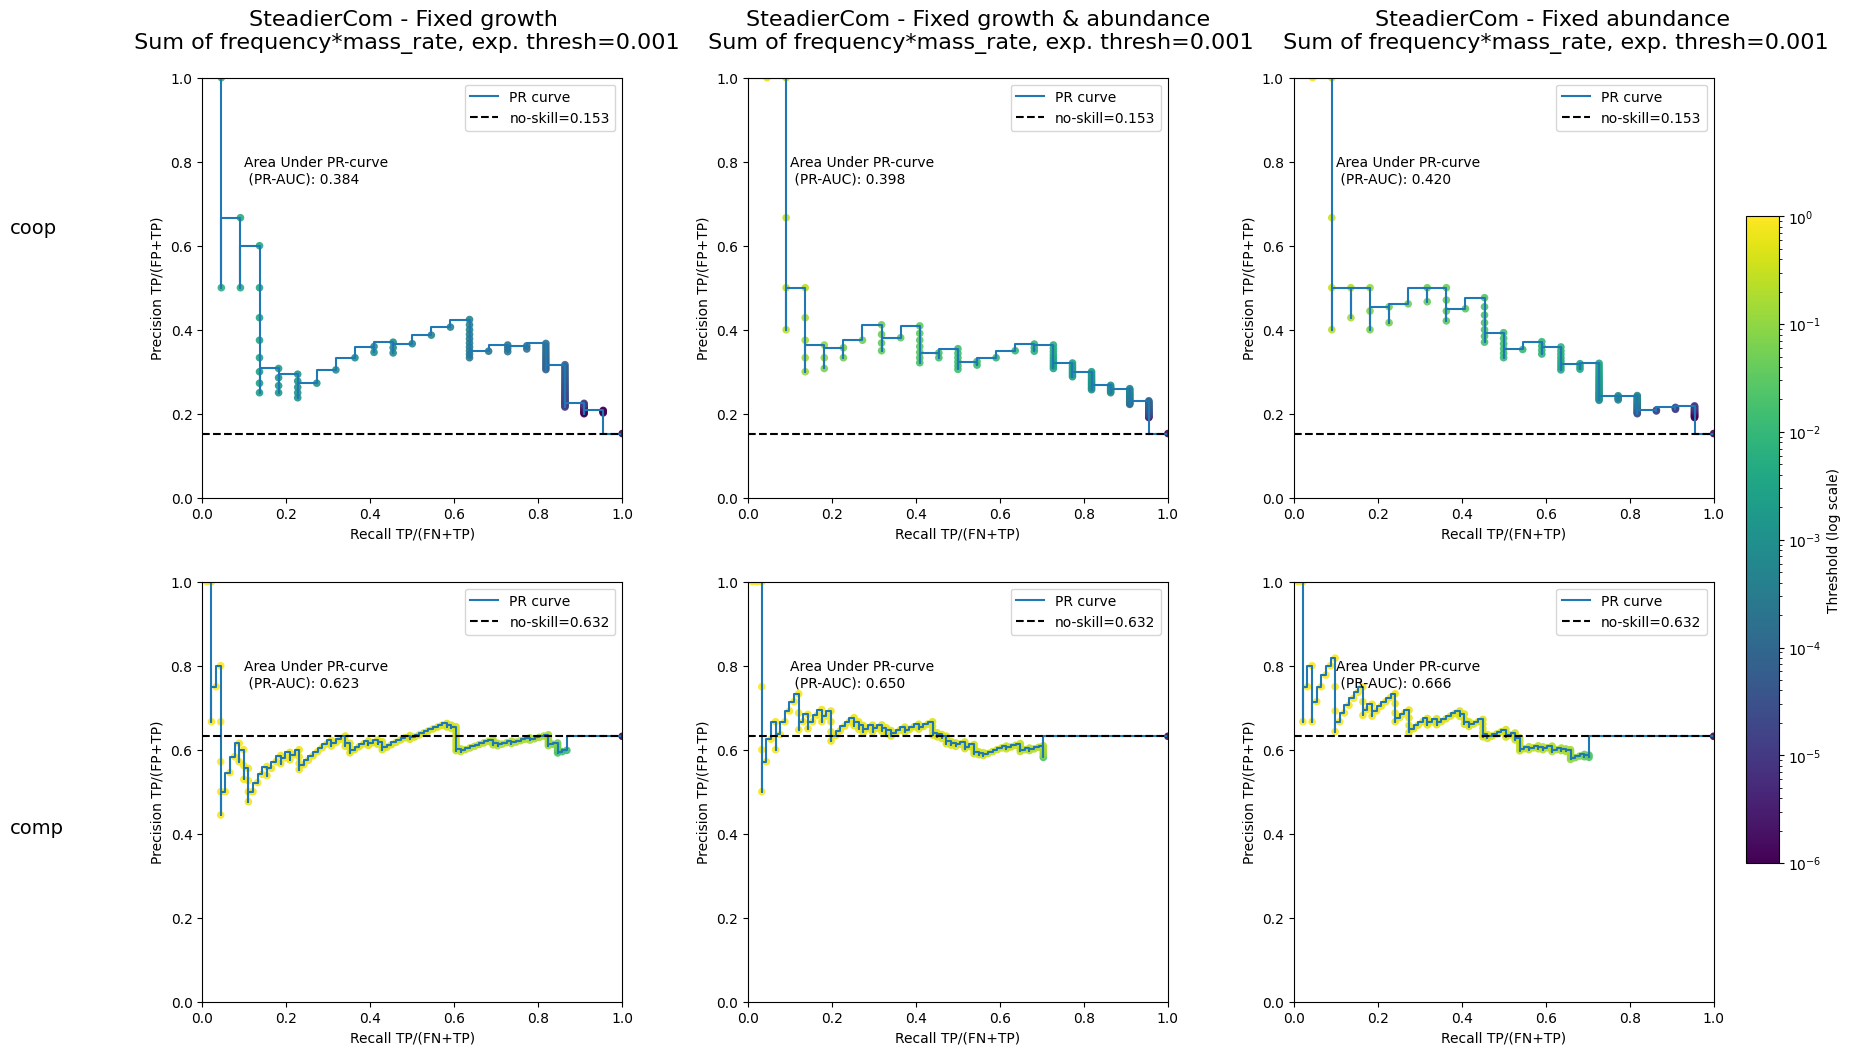

In [32]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                         signal_exp,
                                         PR_or_ROC="PR",
                                         simulation_method="steadiercom",
                                         metric="frequency*mass_rate",
                                         exp_thresh=1e-3)

### SteadierCom - ROC curves

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.


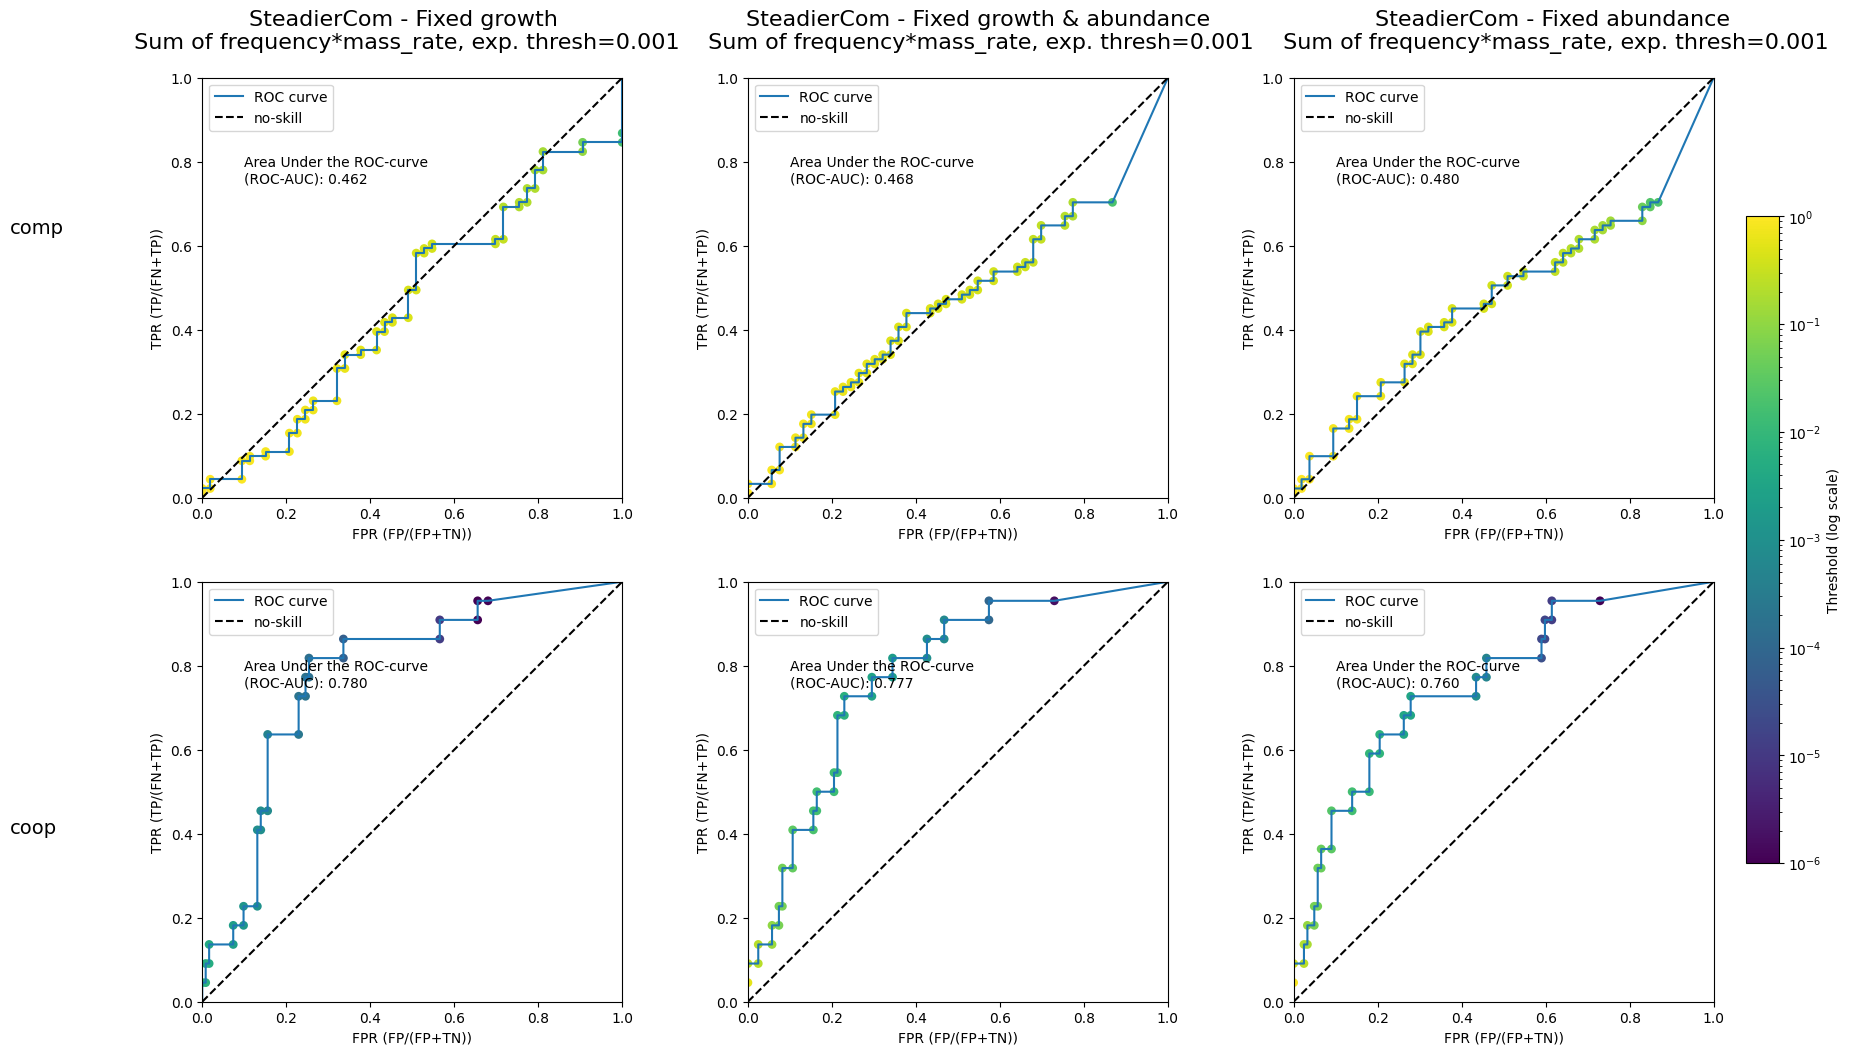

In [30]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                         signal_exp,
                                         PR_or_ROC="ROC",
                                         simulation_method="steadiercom",
                                         metric="frequency*mass_rate",
                                         exp_thresh=1e-3)

### SteadyCom - PR-curves

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.


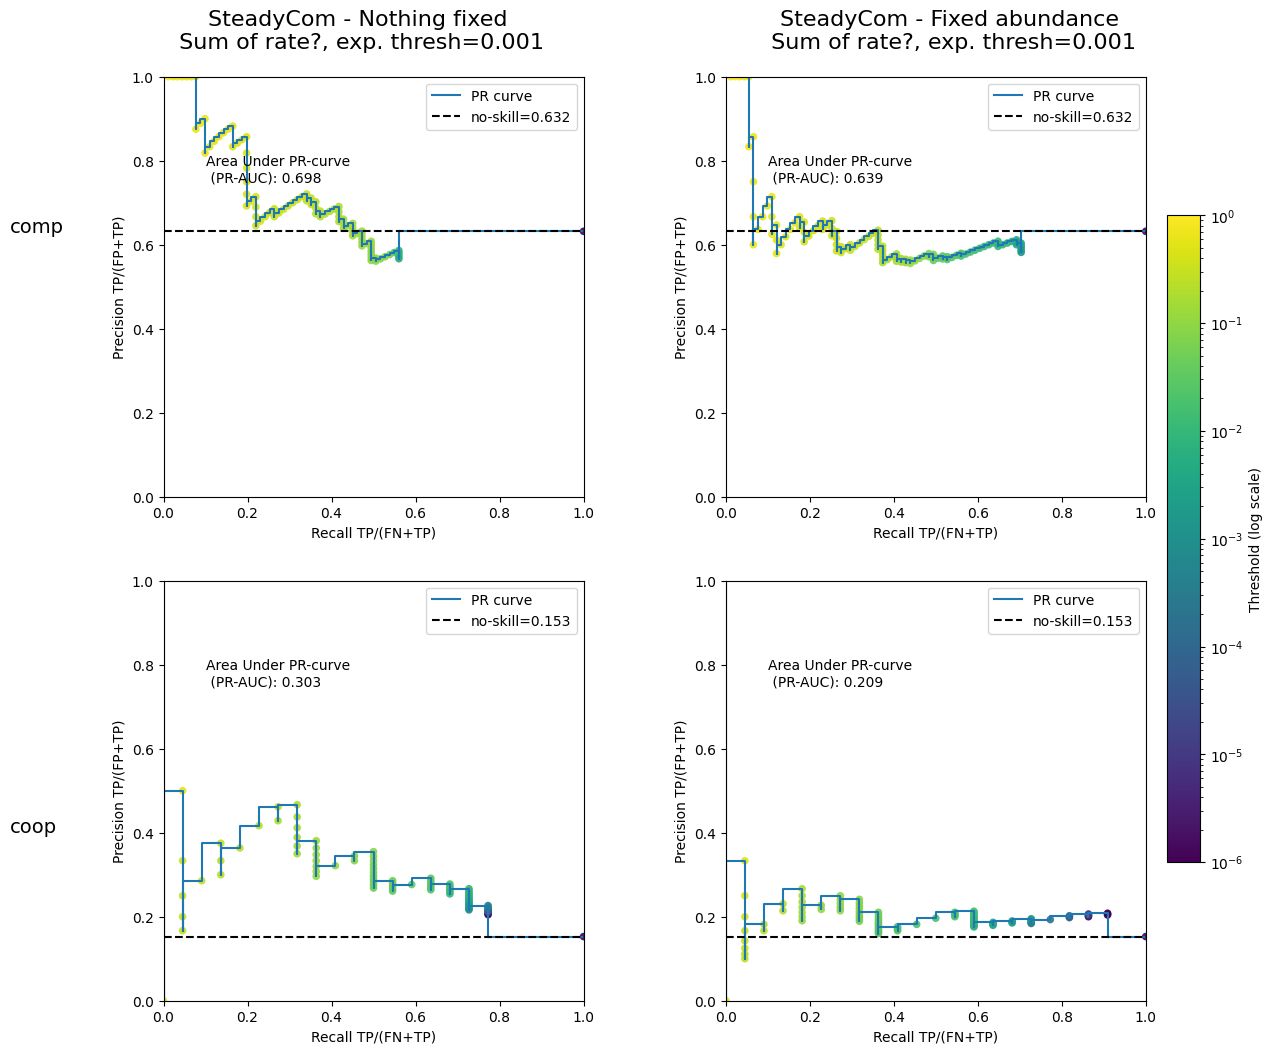

In [35]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                         signal_exp,
                                         PR_or_ROC="PR",
                                         simulation_method="steadycom",
                                         metric="rate?",
                                         exp_thresh=1e-3)

### SteadyCom - ROC-curves

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.


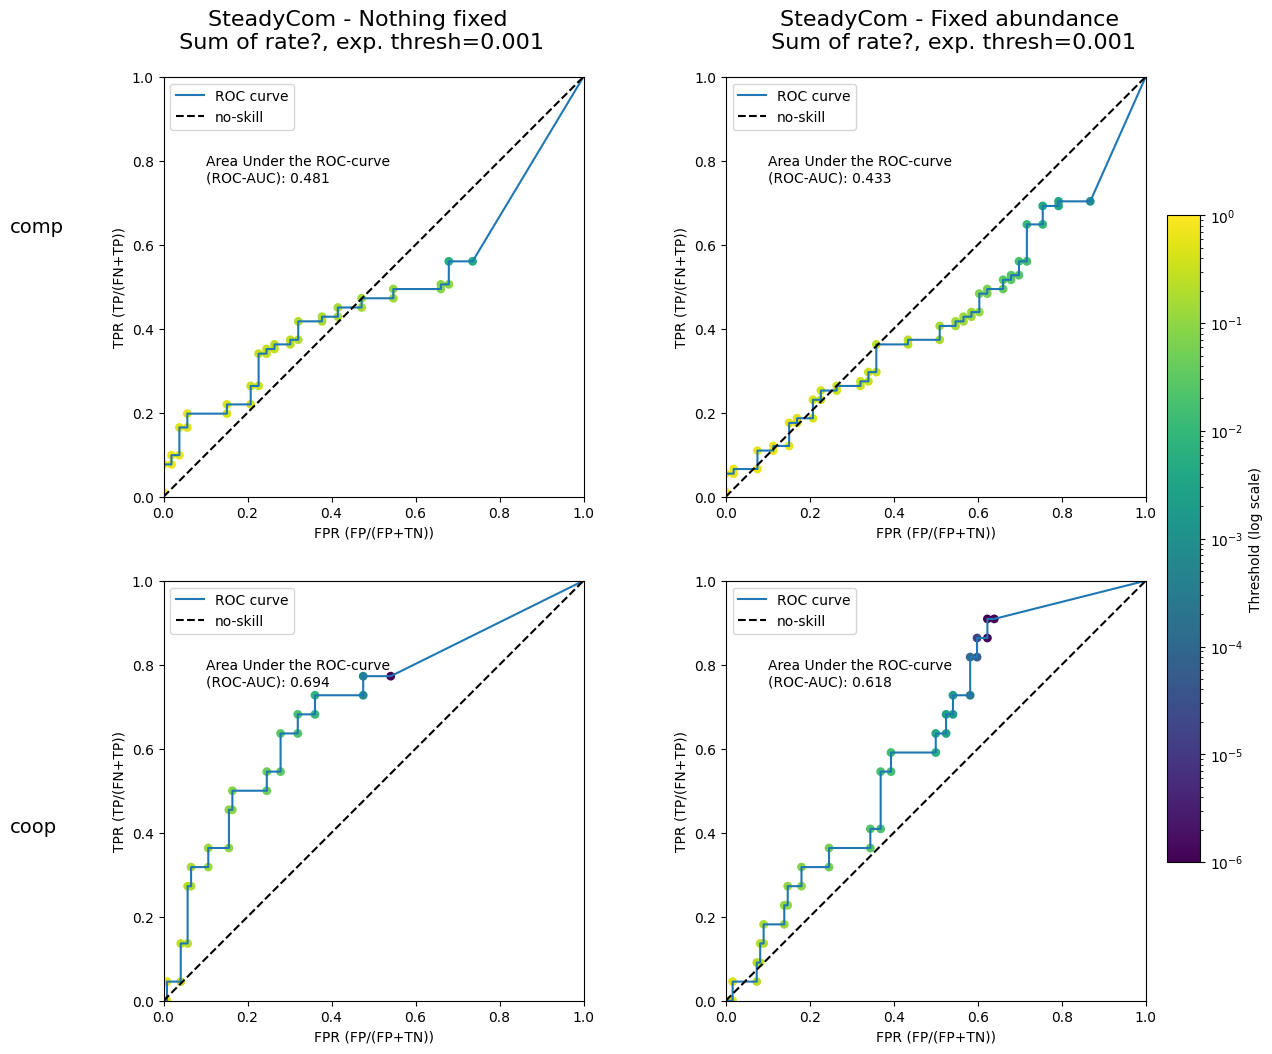

In [66]:
fig,axs = diagnostic.plot_diagnostic_curves_method(simulation_dict,
                                         signal_exp,
                                         PR_or_ROC="ROC",
                                         simulation_method="steadycom",
                                         metric="rate?",
                                         exp_thresh=1e-3)

### For Bacteroides, the simulations 

**...show significant correlation with experimental results in prediction of negative interactions (competition)**

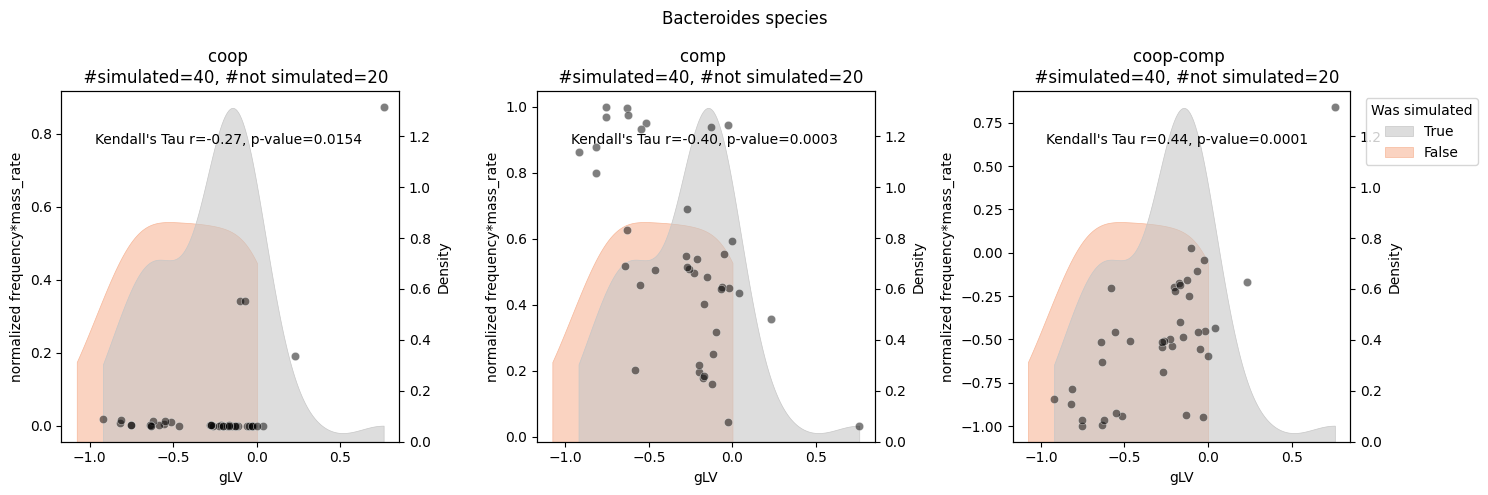

In [78]:
signal_exp_best = signal_exp.loc[(slice(None),["BO","BU","BV","BT","PC"])]

simulated_res = simulation_dict["steadiercom"]["SteadierCom - Fixed abundance"]

metric = "frequency*mass_rate"

fig, axs = plt.subplots(1,3,figsize=(15,5))

for ax,coop_or_comp in zip(axs,["coop","comp","coop-comp"]):
    include_legend = coop_or_comp=="coop-comp"
    correlation.make_scatterplot(simulated_res,
                                 signal_exp_best,
                                 coop_or_comp=coop_or_comp,
                                 metric=metric,
                                 ax=ax,
                                 xlabel="gLV",
                                 ylabel=f"normalized {metric}",
                                 title=coop_or_comp,
                                 include_legend=include_legend,
                                 )    
fig.suptitle("Bacteroides species")
plt.tight_layout()

**...and based on diagnostics, the simulated results give results that are in line with results from gLV model**

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.


Text(0.5, 0.98, 'Bacteroides species')

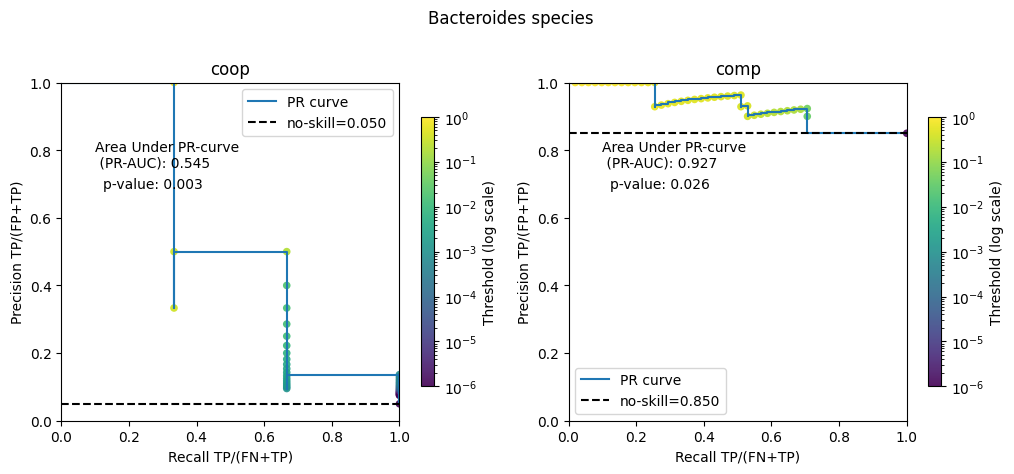

In [71]:
fig, axs = plt.subplots(1,2,figsize=(12,5))

for ax,coop_or_comp in zip(axs,["coop","comp"]):
    diagnostic.plot_diagnostic_curve(simulated_res,
                                 signal_exp_best,
                                 PR_or_ROC="PR",
                                   exp_thresh=1e-3,
                                   coop_or_comp=coop_or_comp,
                                   metric=metric,
                                   ax=ax,
                                   title=coop_or_comp,
                                   plot_cbar=True,
                                   verbose=True)
    
    pvalue_dict = diagnostic._pr_permutation_test(simulated_res,
                                signal_exp_best,
                                exp_thresh=1e-3,
                                coop_or_comp=coop_or_comp,
                                metric=metric,
                                N=1000,
                                verbose=True)

    plt.text(0.27, 0.7, f"p-value: {pvalue_dict['p_value']}", ha='center', va='center', transform=ax.transAxes)
fig.suptitle("Bacteroides species")

### For non-Bacteroides, the simulations

**...show significant correlation with experimental results in predicting cooperation with other species**

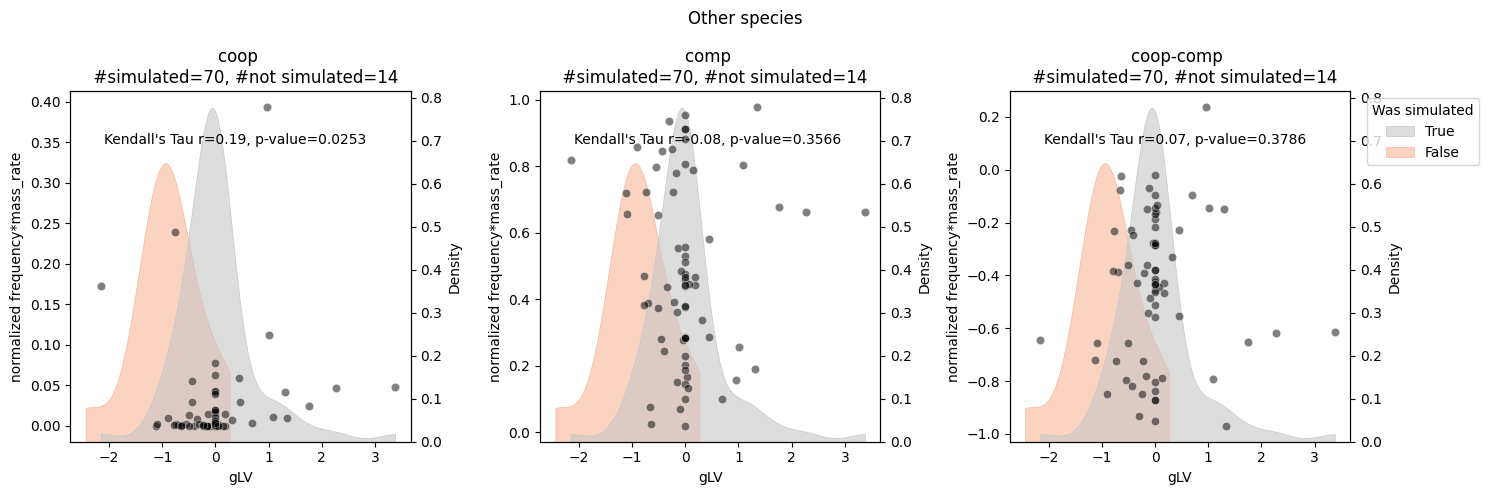

In [74]:
signal_exp_best = signal_exp.loc[(slice(None),["ER","EL","CH","BH","DP","FP","CA"])]

simulated_res = simulation_dict["steadiercom"]["SteadierCom - Fixed abundance"]
metric = "frequency*mass_rate"

fig, axs = plt.subplots(1,3,figsize=(15,5))

for ax,coop_or_comp in zip(axs,["coop","comp","coop-comp"]):
    include_legend = coop_or_comp=="coop-comp"
    correlation.make_scatterplot(simulated_res,
                                 signal_exp_best,
                                 coop_or_comp=coop_or_comp,
                                 metric=metric,
                                 ax=ax,
                                 xlabel="gLV",
                                 ylabel=f"normalized {metric}",
                                 title=coop_or_comp,
                                 include_legend=include_legend,
                                 )    

fig.suptitle("Other species")
plt.tight_layout()

**...and is significantly better than a random model at predicting cooperation based on diagnostics**

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.


Text(0.5, 0.98, 'Other species')

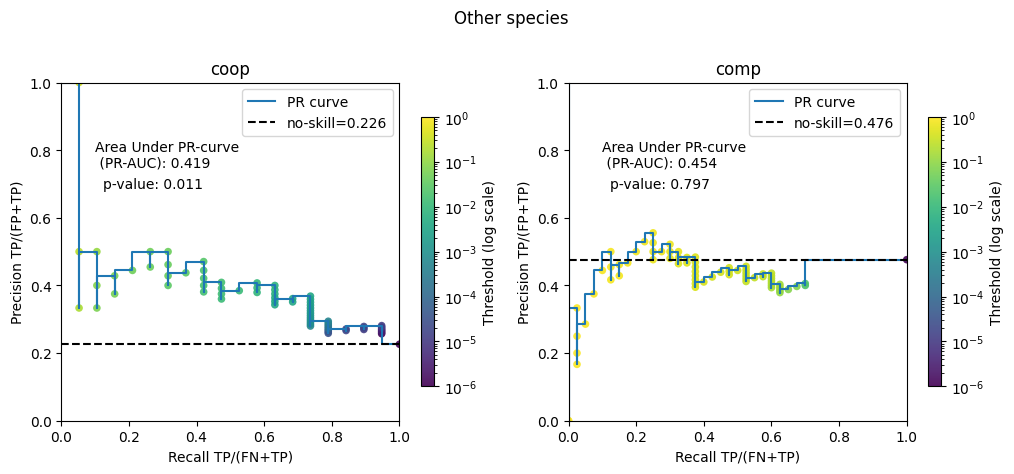

In [73]:
fig, axs = plt.subplots(1,2,figsize=(12,5))

for ax,coop_or_comp in zip(axs,["coop","comp"]):
    diagnostic.plot_diagnostic_curve(simulated_res,
                                 signal_exp_best,
                                 PR_or_ROC="PR",
                                   exp_thresh=1e-3,
                                   coop_or_comp=coop_or_comp,
                                   metric=metric,
                                   ax=ax,
                                   title=coop_or_comp,
                                   plot_cbar=True,
                                   verbose=True)
    
    pvalue_dict = diagnostic._pr_permutation_test(simulated_res,
                                signal_exp_best,
                                exp_thresh=1e-3,
                                coop_or_comp=coop_or_comp,
                                metric=metric,
                                N=1000,
                                verbose=True)

    plt.text(0.27, 0.7, f"p-value: {pvalue_dict['p_value']}", ha='center', va='center', transform=ax.transAxes)
fig.suptitle("Other species")